# Supplementary Figure S4. Penalty weights of the FastRNA base-pair quality score

How much each issue can take off a pair's score. The calibration panels that used to sit here (reference distributions with the penalty severity across them) moved to main-text Figure 3C, which now shows the A·U cWW H-bond distance distribution only.

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if base.name.startswith("PARSE-RNA-Analysis") and (base / "data").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "0.55"
POINT_FACE, POINT_EDGE, FIT = "#C9C9C9", "0.15", "#111111"

CUT = 80.0

LW = ["cWW", "tWW", "cWH", "tWH", "cWS", "tWS", "cHH", "tHH", "cHS", "tHS", "cSS", "tSS"]
TOOLS = ["parse", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
TOOL_LABELS = ["FastRNA", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNET"]

def finish(ax):
    """House chrome: all four spines, thin, outward ticks, no grid."""
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.030, dy=0.012):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

def pair_scores() -> pd.DataFrame:
    return pd.read_json(data_file("reference/scores/pair_scores_uniques_parse.jsonl"), lines=True)

def scored_pairs(lw_only=True) -> pd.DataFrame:
    """Unambiguous, scored per-pair records."""
    df = pair_scores()
    df = df[~df["is_ambiguous"].fillna(False) & df["score"].notna()].copy()
    return df[df["lw_class"].isin(LW)].copy() if lw_only else df

def _resolution(m):
    """Resolution for either method.

    The EM keys carry a non-ASCII Angstrom sign; looking for "(A)" instead drops
    every cryo-EM structure silently.
    """
    if not isinstance(m, dict):
        return None
    return (m.get("EM Diffraction Resolution (Å)") or m.get("Refinement_resolution")
            or m.get("EM Resolution (Å)"))

def structure_scores() -> pd.DataFrame:
    sc = _json("reference/scores/scores_all_uniques.json")["scores"]
    md = _json("reference/metadata/metadata_cache.json")
    vm, nt = md["validation_metrics"], md["nucleotide_counts"]
    rows = []
    for pdb, info in sc.items():
        m = vm.get(pdb) if isinstance(vm.get(pdb), dict) else {}
        rows.append({"pdb": pdb, "pairs_score": info.get("pairs_score"),
                     "backbone_suiteness": info.get("backbone_suiteness"),
                     "n_pairs": info.get("n_pairs", 0),
                     "n_residues_scored": info.get("n_residues_scored", 0),
                     "method": m.get("Experimental_method"),
                     "resolution": _resolution(m), "clashscore": m.get("clashscore"),
                     "rnasuiteness": m.get("rnasuiteness"),
                     "n_nucleotides": nt.get(pdb),
                     "deposited": m.get("Deposition_Date")})
    return pd.DataFrame(rows)

def runtime() -> pd.DataFrame:
    df = pd.read_csv(data_file("benchmark/dssr_PARSE_time_benchmark.csv"))
    df = df[(df["Nucleotides"] > 0) & (df["dssr_avg"] > 0) & (df["parse_avg"] > 0)].copy()
    df["ratio"] = df["dssr_avg"] / df["parse_avg"]
    return df

WEIGHTS = _json("reference/scoring_tables/penalty_weights.json")["penalty_weights"]
ISSUES = list(WEIGHTS)
ISSUE_LABELS = {"distance": "H-bond distance", "hbond_angles": "H-bond angles",
                "incorrect_hbond_count": "H-bond count", "stretch": "Stretch",
                "opening": "Opening", "stagger": "Stagger", "propeller": "Propeller",
                "shear": "Shear", "buckle": "Buckle", "clash": "Clash"}

def hist_grid(fig, spec, df, params, xlabel, cols=3):
    """A small-multiples grid of histograms inside one gridspec cell."""
    rows = int(np.ceil(len(params) / cols))
    sub = spec.subgridspec(rows, cols, wspace=0.42, hspace=0.62)
    axes = []
    for i, p in enumerate(params):
        ax = fig.add_subplot(sub[i // cols, i % cols])
        vals = pd.to_numeric(df[p], errors="coerce").dropna()
        if len(vals) > 20000:
            vals = vals.sample(20000, random_state=1)
        ax.hist(vals, bins=40, color=BLUE, alpha=0.8)
        ax.set_xlabel(p.replace("_", " "), fontsize=7.5)
        ax.tick_params(labelsize=6.5)
        if i % cols == 0:
            ax.set_ylabel("Count", fontsize=7.5)
        finish(ax)
        axes.append(ax)
    return axes

from scipy.stats import gaussian_kde
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Polygon

BP_TYPE, LW_CLASS = "G-C", "cWW"
PAIR_PARAMS = ["shear", "stretch", "stagger", "buckle", "propeller", "opening"]
PAIR_UNITS = {"shear": "\u00c5", "stretch": "\u00c5", "stagger": "\u00c5",
              "buckle": "\u00b0", "propeller": "\u00b0", "opening": "\u00b0"}
HB_PARAMS = ["distance", "donor_angle", "acceptor_angle"]
HB_UNITS = {"distance": "\u00c5", "donor_angle": "\u00b0", "acceptor_angle": "\u00b0"}
HB_LABELS = {"distance": "H-bond distance", "donor_angle": "Donor angle",
             "acceptor_angle": "Acceptor angle"}

FLIP = {"shear", "stagger", "buckle"}
PROSCO_PREFERRED = 5.0
SEV_CMAP = LinearSegmentedColormap.from_list("sev", ["0.82", "#F4D03F", "#E67E22", "#C0392B"])
SEV_NORM = Normalize(0, 1)

PROSCO = _json("reference/scoring_tables/prosco_distributions.json")["prosco_distributions"]
ZTAB = _json("reference/scoring_tables/z_tables.json")

def load_features(kind):
    """kind='pairs'|'hbonds' -> the G-C cWW rows of that reference feature table."""
    df = pd.read_csv(data_file(f"reference/high_quality_features/{kind}.csv"))
    return df[(df["bp_type"] == BP_TYPE) & (df["lw_class"] == LW_CLASS)].reset_index(drop=True)

def per_pdb_weights(pdb_ids):
    """One PDB, one vote: a 4,000-pair ribosome must not outvote 4,000 structures."""
    counts = pdb_ids.value_counts()
    return np.array([1.0 / counts[p] for p in pdb_ids])

def weighted_quantile(values, weights, q):
    order = np.argsort(values)
    v, w = values[order], weights[order]
    cum = np.cumsum(w)
    return float(np.interp(q * cum[-1], cum - w / 2, v))

_to_cg = lambda param, xs: (-xs if param in FLIP else xs)

def _entry(table, group, param):
    c = table[group][param]
    return c.get("C-G/cWW") or c.get("G-C/cWW")

def prosco_at(group, param, xs_gc):
    xs = _to_cg(param, xs_gc)
    c = _entry(PROSCO, group, param)
    lo, hi, n = c["support_lo"], c["support_hi"], c["n_bins"]
    pb = np.array(c["prosco_per_bin"], float)
    return pb[np.clip(((xs - lo) / (hi - lo) * n).astype(int), 0, n - 1)]

def zprime_at(group, param, xs_gc):
    xs = _to_cg(param, xs_gc)
    c = _entry(ZTAB, group, param)
    M, sl, su = c["M"], c["sl"], c["su"]
    return (xs - M) / np.where(xs >= M, su, sl)

def severity_at(group, param, xs_gc):
    """min(1, |Z'|/5) * (5 - ProSco)/5, and exactly 0 inside the preferred tier."""
    pr, z = prosco_at(group, param, xs_gc), zprime_at(group, param, xs_gc)
    ramp = np.clip((PROSCO_PREFERRED - pr) / PROSCO_PREFERRED, 0.0, 1.0)
    return np.where(pr >= PROSCO_PREFERRED, 0.0, np.minimum(1.0, np.abs(z) / 5.0) * ramp)

def _support_gc(group, param):
    c = _entry(PROSCO, group, param)
    lo, hi = c["support_lo"], c["support_hi"]
    return (-hi, -lo) if param in FLIP else (lo, hi)

def _frame_xlim(group, param, med):
    """Widen x just far enough to reach full red on both sides of the median."""
    s_lo, s_hi = _support_gc(group, param)
    xf = np.linspace(s_lo, s_hi, 4000)
    sf = severity_at(group, param, xf)
    L, R = xf[(xf < med) & (sf >= 0.999)], xf[(xf > med) & (sf >= 0.999)]
    xlo = L.max() if L.size else s_lo
    xhi = R.min() if R.size else s_hi
    pad = 0.06 * (xhi - xlo)
    return xlo - pad, xhi + pad

_CAL_CACHE = {}

def _curve(group, param, df, w):
    """KDE curve + severity, cached so the combined figure does not refit."""
    key = (group, param)
    if key not in _CAL_CACHE:
        arr = df[param].to_numpy(float)
        ok = np.isfinite(arr)
        arr, ww = arr[ok], w[ok]
        med = weighted_quantile(arr, ww, 0.5)
        lo_q, hi_q = weighted_quantile(arr, ww, 0.005), weighted_quantile(arr, ww, 0.995)
        keep = (arr >= lo_q) & (arr <= hi_q)
        kde = gaussian_kde(arr[keep], weights=ww[keep])
        xlo, xhi = _frame_xlim(group, param, med)
        xs = np.linspace(xlo, xhi, 600)
        _CAL_CACHE[key] = (xs, kde(xs), severity_at(group, param, xs), med, xlo, xhi)
    return _CAL_CACHE[key]

def cal_panel(ax, df, w, param, units, group, labels=None, ylabel=False):
    """Reference density with the penalty-severity gradient clipped under it."""
    xs, ys, sev, med, xlo, xhi = _curve(group, param, df, w)
    ymax = ys.max() * 1.10
    im = ax.imshow(SEV_CMAP(SEV_NORM(sev))[np.newaxis, :, :], extent=(xlo, xhi, 0, ymax),
                   origin="lower", aspect="auto", interpolation="bilinear", zorder=0)
    clip = Polygon(np.vstack([[xlo, 0], np.column_stack([xs, ys]), [xhi, 0]]),
                   closed=True, facecolor="none", edgecolor="none", zorder=0)
    ax.add_patch(clip)
    im.set_clip_path(clip)
    ax.plot(xs, ys, color="0.15", lw=1.3, zorder=2)
    ax.axvline(med, color="0.15", ls="--", lw=0.8, zorder=2)
    ax.set_xlim(xlo, xhi)
    ax.set_ylim(0, ymax)
    ax.set_yticks([])
    name = (labels or {}).get(param, param.replace("_", " ").capitalize())
    ax.set_xlabel(f"{name} ({units[param]})", fontsize=7.5)
    if ylabel:
        ax.set_ylabel("Weighted density", fontsize=7.5)
    ax.tick_params(labelsize=6.5)
    finish(ax)
    return ax

def cal_grid(fig, spec, kind, params, units, group, labels=None, cols=3):
    df = load_features(kind)
    w = per_pdb_weights(df["pdb_id"])
    rows = int(np.ceil(len(params) / cols))
    sub = spec.subgridspec(rows, cols, wspace=0.22, hspace=0.66)
    return [cal_panel(fig.add_subplot(sub[i // cols, i % cols]), df, w, p, units,
                      group, labels, ylabel=(i % cols == 0))
            for i, p in enumerate(params)]

def severity_colorbar(fig, axes, **kw):
    sm = ScalarMappable(norm=SEV_NORM, cmap=SEV_CMAP)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=axes, **kw)
    cb.set_label("Penalty severity", fontsize=7.5)
    cb.set_ticks([0, 0.5, 1.0])
    cb.set_ticklabels(["0\npreferred", "0.5", "1\nfull"], fontsize=6.5)
    cb.outline.set_linewidth(0.8)
    return cb


## Penalty weights
Relative penalty weight of each scored parameter

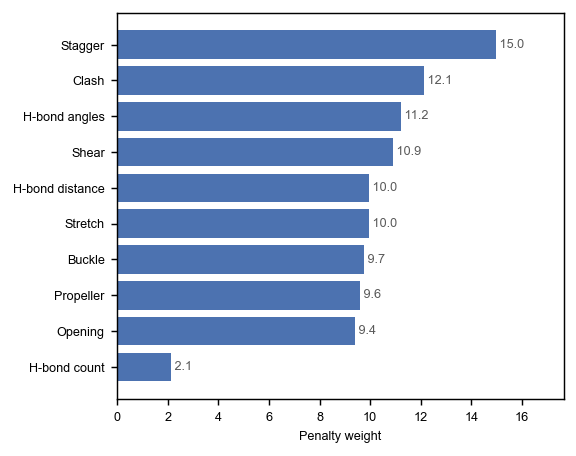

In [2]:
def draw_weights(ax):
    tab = pd.Series(WEIGHTS).sort_values()
    ax.barh([ISSUE_LABELS.get(i, i) for i in tab.index], tab.to_numpy(), color=BLUE)
    for y, v in enumerate(tab.to_numpy()):
        ax.text(v, y, f" {v:.1f}", va="center", ha="left", fontsize=7, color="0.35")
    ax.set_xlim(0, tab.max() * 1.18)
    ax.set_xlabel("Penalty weight")
    finish(ax)


fig, ax = plt.subplots(figsize=(4.6, 3.6))
draw_weights(ax)
fig.tight_layout()
import matplotlib.text as mtext
for _t in fig.findobj(mtext.Text):
    if _t in fig.texts and _t.get_fontweight() in ("bold", 700) and len(_t.get_text().strip()) <= 2:
        _t.set_fontsize(12)
    else:
        _t.set_fontsize(7)
save(fig, "figures/supplemental/figS4.png")
plt.show()